## 1. Load the data

A first look at PORTIA: how much data we have, what the labels look like, and a few recordings.

Run `uv run python data-prep/prepare.py` from the repo root first, then run this notebook top to bottom. 

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from IPython.display import Audio, display
from scipy import signal

root = Path.cwd()
if root.name == 'eda':
    root = root.parent
data = root / 'data'
audio_dir = data / 'PORTIA_Clean_Release' / 'audio'
classes = ['tug', 'pilot', 'cargo', 'passenger', 'support', 'tanker', 'other']
splits = ['train', 'val', 'test']
sns.set_theme(style='whitegrid')

# Keep vessel IDs as strings and recording times as datetimes.
id_columns = {'primary_mmsi': 'string', 'all_mmsis': 'string'}
manifest = pd.read_csv(data / 'processed/manifests.csv', dtype=id_columns)
pilot = pd.read_csv(data / 'processed/pilot.csv', dtype=id_columns)
for table in [manifest, pilot]:
    table['window_start'] = pd.to_datetime(table['window_start'], utc=True)

# Task rows can share a WAV, so show both row counts and unique recordings.
display(pd.DataFrame({
    'rows': [len(manifest), len(pilot)],
    'unique_wavs': [manifest['audio_path'].nunique(), pilot['audio_path'].nunique()],
}, index=['full metadata', 'audio sample']))
display(manifest.head())

,rows,unique_wavs
full metadata,111770,97400
audio sample,252,244


,audio_path,source,is_background,n_vessels,primary_mmsi,primary_class,primary_dist,all_mmsis,timestamp,tug,...,tanker_dist,other,other_dist,split,binary_label,task,official_split,window_start,temporal_split,conflicting_target
0,20250518_090234.599908368.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:34+00:00,0,...,NaN,0,NaN,train,0.0,binary,train,2025-05-18 09:02:34.599908368+00:00,train,False
1,20250518_090237.644671816.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:37+00:00,0,...,NaN,0,NaN,train,0.0,binary,train,2025-05-18 09:02:37.644671816+00:00,train,False
2,20250518_090243.736697350.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:43+00:00,0,...,NaN,0,NaN,train,0.0,binary,train,2025-05-18 09:02:43.736697350+00:00,train,False
3,20250518_090246.781061066.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:46+00:00,0,...,NaN,0,NaN,train,0.0,binary,train,2025-05-18 09:02:46.781061066+00:00,train,False
4,20250518_090249.827123897.wav,windowed,1,0,<NA>,NaN,NaN,225998087,2025-05-18 09:02:49+00:00,0,...,NaN,0,NaN,train,0.0,binary,train,2025-05-18 09:02:49.827123897+00:00,train,False


## 2. Labels and missing values

Labels come from AIS vessel reports, not verified audible sources. A primary vessel type does not mean there is only one vessel.

Missing distances are often expected when a class is absent. `binary_label` only applies to the binary task. Keep unknown targets missing rather than filling them with zero.

In [2]:
# Show the columns with missing values, separately for each task.
missing = pd.DataFrame({
    task: group.isna().sum() for task, group in manifest.groupby('task')
})
display(missing.loc[missing.sum(axis=1).gt(0)])

binary = manifest.loc[manifest['task'].eq('binary')]
single = manifest.loc[manifest['task'].eq('single')]
multilabel = manifest.loc[manifest['task'].eq('multilabel')]

# Conflicts were flagged during preparation; all occurrences stay in the EDA table.
conflicts = manifest.loc[manifest['conflicting_target']]
print(f'Missing binary targets: {binary["binary_label"].isna().sum():,}')
print(f'Conflicting WAVs: {conflicts["audio_path"].nunique():,}')
print(f'Single-target rows with multiple vessels: {single["n_vessels"].gt(1).mean():.1%}')

,binary,multilabel,single
primary_mmsi,18389,0,0
primary_class,18389,0,0
primary_dist,19968,3263,7999
all_mmsis,18180,0,0
tug_dist,24577,12974,27867
pilot_dist,27561,18085,26159
cargo_dist,29938,21586,33212
passenger_dist,32447,28563,35403
support_dist,33017,27426,32136
tanker_dist,34608,30884,36052


Missing binary targets: 1,579
Conflicting WAVs: 315
Single-target rows with multiple vessels: 16.3%


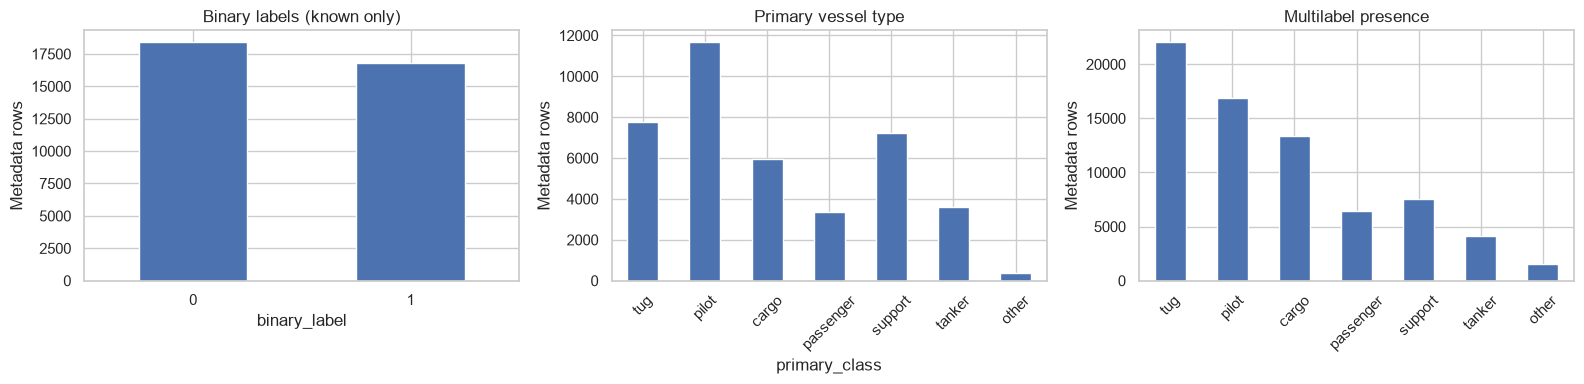

In [3]:
# Binary counts use observed labels. Multilabel counts can overlap.
binary_counts = binary['binary_label'].value_counts().reindex([0, 1], fill_value=0)
primary_counts = single['primary_class'].value_counts().reindex(classes, fill_value=0)
presence_counts = multilabel[classes].eq(1).sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
binary_counts.plot.bar(ax=axes[0], rot=0, title='Binary labels (known only)')
primary_counts.plot.bar(ax=axes[1], rot=45, title='Primary vessel type')
presence_counts.plot.bar(ax=axes[2], rot=45, title='Multilabel presence')
for ax in axes:
    ax.set_ylabel('Metadata rows')
fig.tight_layout()
plt.show()

## 3. Splits and shared recordings

The official splits can share recordings. Preparation instead splits whole recording days in chronological order.

Compare the full eligible pools with our sample. A split with 15% of recording days does not necessarily have 15% of the rows.

official_split,train,val,test
task,,,
binary,25593,5506,5511
multilabel,19609,8141,7246
single,20740,11790,7466


WAVs shared across official splits: 147


eligible_wavs  sampled_wavs
task       temporal_split                             
binary     test                     2901            30
           train                   31623            30
           val                        45            30
multilabel test                     3678            30
           train                   31306            30
           val                        12            12
single     test                     3416            30
           train                   36528            30
           val                        52            30

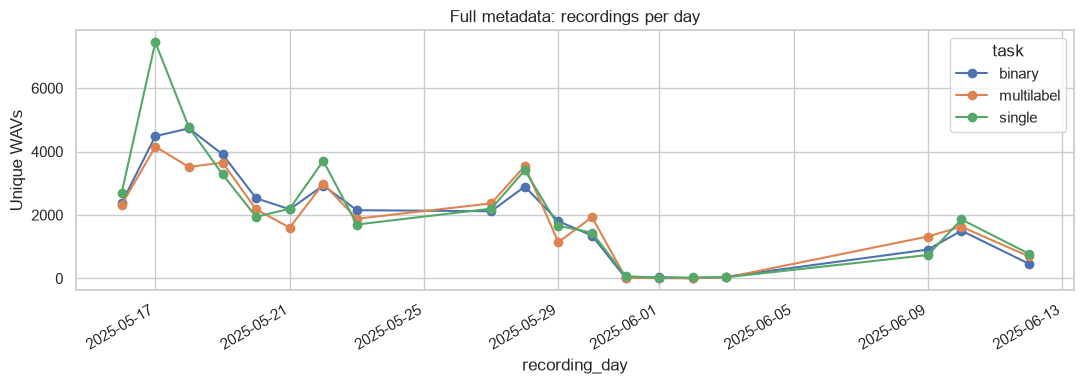

In [4]:
# Count unique WAVs per task, rather than adding repeated source rows.
official_counts = manifest.groupby(['task', 'official_split'])['audio_path'].nunique()
display(official_counts.unstack().reindex(columns=splits))

official_membership = manifest.groupby(['task', 'audio_path'])['official_split'].nunique()
shared_paths = official_membership.loc[official_membership.gt(1)]
print(f'WAVs shared across official splits: '
      f'{shared_paths.index.get_level_values("audio_path").nunique():,}')

# Use the same target exclusions as preparation, before comparing with the pilot.
missing_binary = manifest['task'].eq('binary') & manifest['binary_label'].isna()
eligible = manifest.loc[~(manifest['conflicting_target'] | missing_binary)]
eligible_counts = eligible.groupby(['task', 'temporal_split'])['audio_path'].nunique()
pilot_counts = pilot.groupby(['task', 'split'])['audio_path'].nunique()
pilot_counts.index.names = eligible_counts.index.names
coverage = pd.DataFrame({'eligible_wavs': eligible_counts, 'sampled_wavs': pilot_counts})
display(coverage)

# Show when recordings were made. Each line counts unique WAVs for one task.
daily = manifest.assign(recording_day=manifest['window_start'].dt.floor('D'))
daily_counts = daily.groupby(['recording_day', 'task'])['audio_path'].nunique().unstack()
daily_counts.plot(figsize=(11, 4), marker='o', title='Full metadata: recordings per day')
plt.ylabel('Unique WAVs')
plt.tight_layout()
plt.show()

## 4. Check a few recordings

Check file lengths in the selected sample, then listen to three binary-training examples. This says nothing about audio quality across the whole archive.

Waveform values are digital amplitudes, not calibrated sound pressure. Playback and spectrograms average the channels, which can lose information.

In [5]:
# Inspect only selected WAVs, not every file left in the download cache.
audio_rows = []
for name in pilot['audio_path'].drop_duplicates():
    try:
        info = sf.info(audio_dir / name)
        audio_rows.append({
            'audio_path': name, 'frames': info.frames, 'seconds': info.duration,
            'sample_rate': info.samplerate, 'channels': info.channels,
        })
    except (OSError, RuntimeError) as error:
        audio_rows.append({'audio_path': name, 'error': str(error)})
audio_info = pd.DataFrame(audio_rows)
display(audio_info[['seconds', 'sample_rate', 'channels']].describe())

# An empty recording has a header but cannot be used for audio features.
unusable = audio_info['frames'].fillna(0).lt(2)
display(audio_info.loc[unusable])
print(f'{len(audio_info)} selected WAVs checked; {unusable.sum()} short or unreadable.')

,seconds,sample_rate,channels
count,244.000000,244.0,244.0
mean,2.987705,32000.0,4.0
std,0.192055,0.0,0.0
min,0.000000,32000.0,4.0
25%,3.000000,32000.0,4.0
50%,3.000000,32000.0,4.0
75%,3.000000,32000.0,4.0
max,3.000000,32000.0,4.0


,audio_path,frames,seconds,sample_rate,channels
237,20250602_084723.477218059.wav,0,0.0,32000,4


244 selected WAVs checked; 1 short or unreadable.


20250520_115744.017865646.wav: binary=0, vessels=0


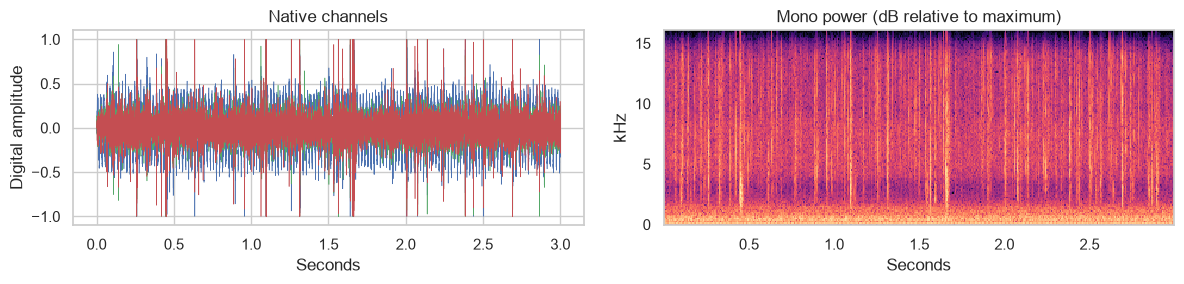

20250527_153646.171911686.wav: binary=1, vessels=3


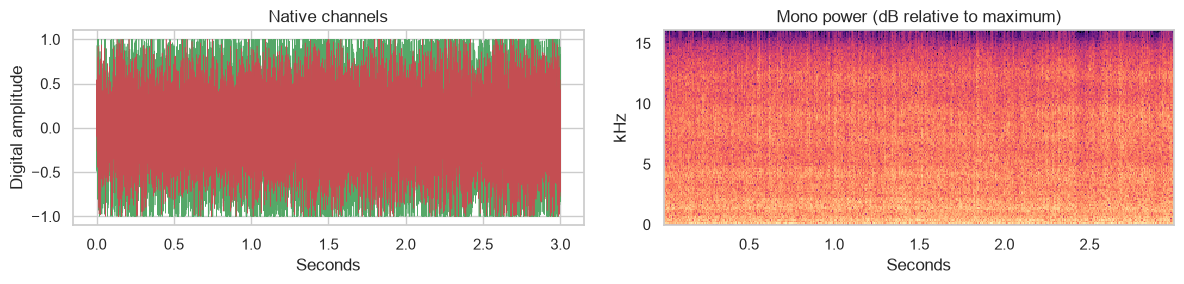

20250527_134239.981997090.wav: binary=1, vessels=4


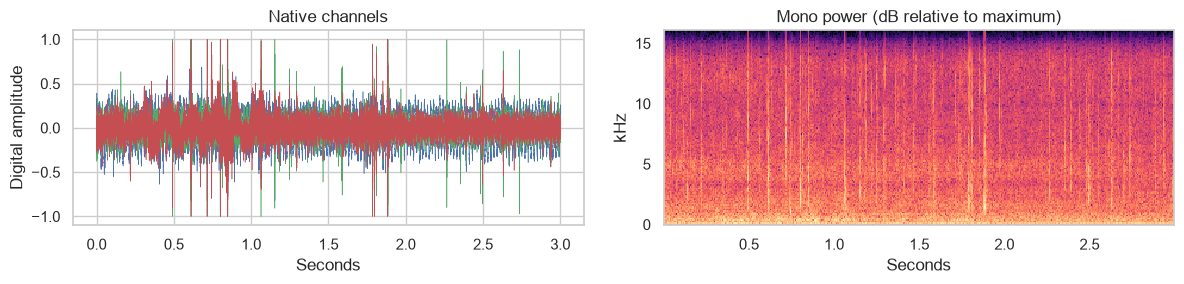

In [6]:
# Pick three examples from binary training rows, with a fixed seed.
examples = pilot.loc[pilot['task'].eq('binary') & pilot['split'].eq('train')]
examples = examples.drop_duplicates('audio_path')
examples = examples.sample(n=min(3, len(examples)), random_state=42)

for row in examples.itertuples(index=False):
    try:
        samples, rate = sf.read(audio_dir / row.audio_path, always_2d=True)
    except (OSError, RuntimeError) as error:
        print(f'Skipping {row.audio_path}: {error}')
        continue
    if len(samples) < 2 or not np.isfinite(samples).all():
        print(f'Skipping {row.audio_path}: short or nonfinite samples')
        continue

    # Show each channel, then use their mean for playback and the spectrum.
    mono = samples.mean(axis=1)
    frequencies, times, power = signal.spectrogram(mono, fs=rate)
    relative_power = power / max(power.max(), np.finfo(float).tiny)
    relative_db = 10 * np.log10(np.maximum(relative_power, 1e-10))

    print(f'{row.audio_path}: binary={row.binary_label:g}, vessels={row.n_vessels}')
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    axes[0].plot(np.arange(len(samples)) / rate, samples, linewidth=0.4)
    axes[0].set(title='Native channels', xlabel='Seconds', ylabel='Digital amplitude')
    axes[1].pcolormesh(times, frequencies / 1000, relative_db,
                       shading='auto', cmap='magma', vmin=-100, vmax=0)
    axes[1].set(title='Mono power (dB relative to maximum)',
                xlabel='Seconds', ylabel='kHz')
    fig.tight_layout()
    plt.show()
    display(Audio(mono, rate=rate, normalize=False))